# 11 · Measuring the decisions, and guarding the test set

**The question this step answers:** once a method has made its decisions, how good are they, how sure can we be of those numbers, and how do we make sure the final exam (the test split) isn't used to tune anything?

**Where it sits in the pipeline:** after the Mapper (notebook 10). The command `python -m d1.evaluation.run_mapping --split dev --method <name>` runs a trained method on a split and writes `reports/results/<run>/`:
- `metrics.json`: every measurement, with 95% intervals;
- `tables.md`: the same as readable tables;
- `decisions.csv`: one line per account.

This notebook reads those files for the two baselines, so it runs in seconds.

**The code:** `src/d1/evaluation/metrics.py` (the measurements) and `src/d1/evaluation/run_mapping.py` (the run and the guard).

> **Re-run after step 12 and the name cleanup (2026-11-06).** The baselines here use `group_text: average` from step 12: each group is scored on its names and on its names plus description, and the two scores are averaged. The account names are the cleaned ones, without company, bank or brand names (notebook 04, section 3b).

In [1]:
import json
from collections import Counter
from random import Random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from d1.config import REPO_ROOT, load_config
from d1.datagen.standard_chart import load_standard_chart
from d1.evaluation.plotting import (
    BLUE_RAMP, COLORS, INK, INK_2, LANGUAGE_COLORS, MUTED, SINGLE, SOURCE_COLORS, SURFACE, apply_style, pct, short,
)

config = load_config()
chart = load_standard_chart(config.data.chart_path, expected=config.data.expected_groups)
by_code = {a.code: a for a in chart}
apply_style()
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 60)

import contextlib, glob, io
from d1.evaluation.metrics import bootstrap_ci, paired_bootstrap_diff
from d1.evaluation.plotting import METHOD_COLORS

TARGET = config.models.mapping.target_precision
runs = {}
for m in ["fuzzy", "embeddings"]:
    folder = sorted(glob.glob(str(REPO_ROOT / "reports" / "results" / f"*-dev-{m}")))[-1]  # the latest dev run
    runs[m] = {"metrics": json.loads(open(f"{folder}/metrics.json").read()),
               "decisions": pd.read_csv(f"{folder}/decisions.csv", dtype={"target_code": str, "chosen_code": str}, keep_default_na=False)}
    print(f"{m:10} -> reports/results/{folder.rsplit('/', 1)[1]}")

fuzzy      -> reports/results/20261106-080433-dev-fuzzy
embeddings -> reports/results/20261106-080447-dev-embeddings


## 1. The four things that can happen to one account

Every account ends in one of four boxes: auto-mapped or sent to review, and the method's pick right or wrong. Four real dev accounts with the embeddings method, one per box:

In [2]:
d = runs["embeddings"]["decisions"]
d["right"] = d["right"].astype(bool)
d["box"] = np.select([(d.decision_path == "auto") & d.right, (d.decision_path == "auto") & ~d.right, d.right], ["auto, right", "auto, WRONG", "review, suggestion right"], "review, suggestion wrong")
examples = d.groupby("box").head(1).set_index("box").loc[["auto, right", "auto, WRONG", "review, suggestion right", "review, suggestion wrong"]]
examples["pick"] = examples["chosen_code"].map(lambda c: f"{c} {by_code[c].name_en}")
examples["right group"] = examples["target_code"].map(lambda c: f"{c} {by_code[c].name_en}")
display(examples[["name", "source", "pick", "right group", "confidence"]])

,name,source,pick,right group,confidence
box,,,,,
"auto, right",Terugnemingen van waardeverminderingen op geldbeleggingen,rules,124 Decrease in Amounts Written Down on Current Investments,124 Decrease in Amounts Written Down on Current Investments,0.978728
"auto, WRONG",Als herstructureringskosten ge,rules,204 Restructuring Costs,649 Operating Charges Carried to Assets as Restructuring Costs (-),0.982784
"review, suggestion right",Voorzieningen voor pensioenen en soortgelijke verplichtingen,rules,160 Provisions for Pensions and Similar Obligations,160 Provisions for Pensions and Similar Obligations,0.825214
"review, suggestion wrong",ANDERE VORD.,rules,700 Sales and Services Rendered,285 Other Amounts Receivable,0.122055


- **auto, right:** mapped without a person, correctly. That's the work saved.
- **auto, WRONG:** mapped without a person, incorrectly. **That's the costly box:** a wrong mapping in the books that nobody looked at.
- **review:** a person checks it. Whether the suggestion was right only affects how fast the review goes.

How many dev accounts land in each box:

In [3]:
boxes = pd.crosstab(d["decision_path"].map({"auto": "auto-mapped", "review": "sent to review"}), d["right"].map({True: "pick right", False: "pick wrong"}), margins=True, margins_name="total")
display(boxes)

right,pick right,pick wrong,total
decision_path,,,
auto-mapped,1102,22,1124
sent to review,1358,1018,2376
total,2460,1040,3500


Every headline number is a count from that table:
- **auto-share** = auto-mapped ÷ all accounts: how much work is saved;
- **precision of the auto-mapped** = auto-mapped right ÷ auto-mapped: how safe that is (target 98%);
- **review share** = sent to review ÷ all accounts;
- **top-1** = pick right ÷ all accounts, whatever the decision; **top-3** = right group among the first 3 candidates;
- **recall@10** = right group on the shortlist (notebook 08).

## 2. The two baselines, with their uncertainty

The 95% intervals come from resampling the 70 dev **companies** 2,000 times, as in notebook 08: accounts of one company look alike, so they don't count as independent.

,auto-mapped,95% interval,precision of auto-mapped,95% interval,top-1,top-3,recall@10
method,,,,,,,
fuzzy,31.6%,25.5% – 37.4%,98.6%,97.5% – 99.3%,57.9%,67.5%,92.6%
embeddings,32.1%,27.1% – 36.9%,98.0%,97.0% – 98.9%,70.3%,84.8%,92.6%


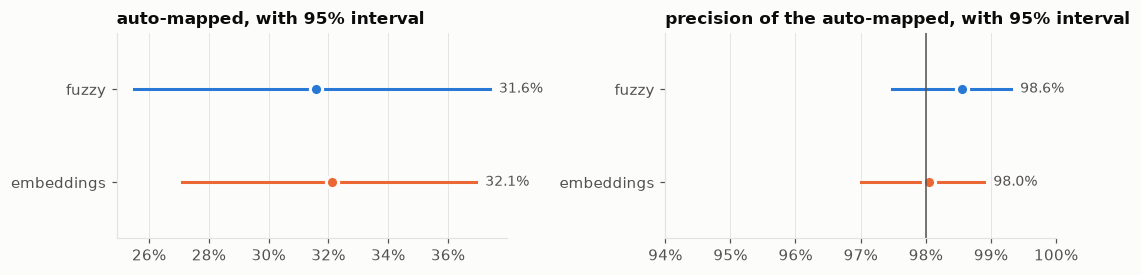

In [4]:
rows = []
for m, r in runs.items():
    o = r["metrics"]["overall"]
    rows.append({"method": m, "auto-mapped": o["auto_share"], "95% interval": f"{o['auto_share_ci'][0]:.1%} – {o['auto_share_ci'][1]:.1%}",
                 "precision of auto-mapped": o["auto_precision"], "95% interval ": f"{o['auto_precision_ci'][0]:.1%} – {o['auto_precision_ci'][1]:.1%}",
                 "top-1": o["top1"], "top-3": o["top3"], f"recall@{o['k']}": o["recall_at_k"]})
display(pd.DataFrame(rows).set_index("method").style.format({c: "{:.1%}" for c in ["auto-mapped", "precision of auto-mapped", "top-1", "top-3", "recall@10"]}))

fig, axes = plt.subplots(1, 2, figsize=(10, 2.6))
for ax, key, title in [(axes[0], "auto_share", "auto-mapped"), (axes[1], "auto_precision", "precision of the auto-mapped")]:
    for y, (m, r) in enumerate(runs.items()):
        o = r["metrics"]["overall"]
        low, high = o[f"{key}_ci"]
        ax.plot([low, high], [y, y], color=METHOD_COLORS[m], linewidth=2)
        ax.plot(o[key], y, "o", color=METHOD_COLORS[m], markersize=8, markeredgecolor=SURFACE, markeredgewidth=2)
        ax.annotate(f"{o[key]:.1%}", (high, y), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=INK_2)
    ax.set_yticks(range(len(runs)), list(runs))
    ax.set_ylim(-0.6, len(runs) - 0.4)
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(pct())
    ax.grid(axis="y", visible=False)
    ax.set_title(f"{title}, with 95% interval")
axes[1].axvline(TARGET, color=INK_2, linewidth=1)
axes[1].set_xlim(0.94, 1.0)
plt.tight_layout()
plt.show()

Both precision intervals reach a little below 98%. On dev, the target is met on average, not with certainty, which is what the test split will check once.

**Fuzzy against embeddings, paired.** Both methods decided on the *same* accounts, so their difference is measured on the same resampled companies. That's tighter than comparing the two intervals above. Two differences matter: how many more accounts fuzzy auto-maps, and how many more **wrong** auto-mappings it lets through per 1,000 accounts:

In [5]:
f, e = runs["fuzzy"]["decisions"], runs["embeddings"]["decisions"]
assert (f["account_id"].values == e["account_id"].values).all()
companies = f["company_id"].to_numpy()
f_auto, e_auto = (f["decision_path"] == "auto").to_numpy(float), (e["decision_path"] == "auto").to_numpy(float)
f_bad = ((f["decision_path"] == "auto") & (f["right"] == 0)).to_numpy(float)
e_bad = ((e["decision_path"] == "auto") & (e["right"] == 0)).to_numpy(float)
rows = []
for label, a, b, scale in [("auto-mapped (share of accounts)", f_auto, e_auto, 1), ("wrong auto-mappings per 1,000 accounts", f_bad, e_bad, 1000)]:
    diff, low, high = paired_bootstrap_diff(a, b, n=2000, seed=0, groups=companies)
    rows.append({"measure": label, "fuzzy": a.mean() * scale, "embeddings": b.mean() * scale, "fuzzy − embeddings": diff * scale,
                 "95% interval": f"{low * scale:+.3g} to {high * scale:+.3g}"})
display(pd.DataFrame(rows).set_index("measure").round(3))

,fuzzy,embeddings,fuzzy − embeddings,95% interval
measure,,,,
auto-mapped (share of accounts),0.316,0.321,-0.005,-0.032 to +0.0209
"wrong auto-mappings per 1,000 accounts",4.571,6.286,-1.714,-4.86 to +1.43


The two save about the same work: fuzzy auto-maps half a point less of dev, and the interval (−3.2 to +2.1 points) includes zero. Fuzzy also lets through about 1.7 fewer wrong mappings per 1,000 accounts, an interval that includes zero too. Overall, on dev, the two baselines can't be told apart. The next section shows that they get there in very different ways.

## 3. Where the numbers come from: by source

The same measurements per source, straight from `metrics.json`:

In [6]:
rows = []
for m, r in runs.items():
    for b in r["metrics"]["breakdowns"]["source"]:
        rows.append({"method": m, "source": b["value"], "accounts": b["n"], "auto-mapped": b["auto_share"],
                     "precision of auto-mapped": b["auto_precision"], "top-1": b["top1"]})
display(pd.DataFrame(rows).set_index(["method", "source"]).style.format({"auto-mapped": "{:.1%}", "precision of auto-mapped": "{:.1%}", "top-1": "{:.1%}"}))

The overall 98% comes mostly from rule-based accounts. On LLM-written accounts both auto-map few: embeddings 126 at 88%, fuzzy 39 at 59%. The bar stays pooled over all accounts (decided before Task 3.5, because the LLM-written accounts are the most realistic), and this per-source view comes with every run so a gap like fuzzy's stays visible.

The interval of the LLM-written precision shows how little the dev data can say about it: for fuzzy it rests on only 39 auto-mapped accounts.

In [7]:
for m, r in runs.items():
    x = r["decisions"]
    llm = (x["source"] == "llm").to_numpy()
    auto = (x["decision_path"] == "auto").to_numpy()
    right = (x["right"] == 1).to_numpy()
    sub = np.where(llm)[0]
    low, high = bootstrap_ci(lambda idx: right[sub][idx][auto[sub][idx]].mean() if auto[sub][idx].any() else None,
                             len(sub), groups=x["company_id"].to_numpy()[sub])
    print(f"{m:10} LLM-written accounts auto-mapped: {int((auto & llm).sum()):3d}; precision {right[auto & llm].mean():.1%} (95%: {low:.1%} – {high:.1%})")

fuzzy      LLM-written accounts auto-mapped:  39; precision 59.0% (95%: 44.7% – 72.4%)
embeddings LLM-written accounts auto-mapped: 126; precision 88.1% (95%: 82.9% – 93.3%)


## 4. A bug the evaluation caught: training and evaluation disagreed

The first evaluation run of fuzzy (Task 2.5, before step 12 and the name cleanup) said **95.8%** precision, while training had reported 98.1% for the same dev accounts. The cause:
1. Training chose the threshold on *out-of-fold* probabilities (each account predicted by a calibrator that never saw it).
2. It then saved a calibrator refitted on *all* of dev, and that's the one the Mapper uses. Its probabilities differ slightly.
3. Fuzzy gives many accounts exactly the same scores. For example, it gives a top score of 1.0 whenever a short group name appears inside the account name. Accounts with the same scores get the same probability, so fuzzy's confidences come in tall blocks. One block of 59 tied accounts sat right at the threshold (between 0.8528 and 0.8541), only 42% of them right, and the refitted calibrator moved it to the auto side.

The blocks are still clearly visible in fuzzy's confidences today. With the current data the two thresholds happen to fall on the same value, so no block sits between them:

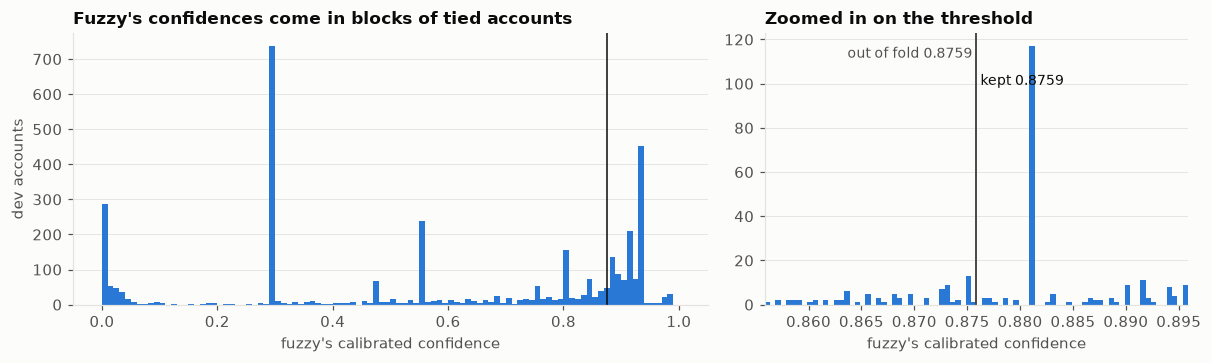

out-of-fold threshold 0.8759, kept threshold 0.8759: no accounts between them


In [8]:
fz = runs["fuzzy"]["decisions"]
t = runs["fuzzy"]["metrics"]["thresholds"]["t_auto"]
conf = fz["confidence"].astype(float)
t_old = json.loads((REPO_ROOT / "artifacts" / "methods" / "fuzzy" / "dev_summary.json").read_text())["out_of_fold"]["t_auto"]
edge = conf[(conf >= t_old) & (conf < t)]  # the accounts between the old and the new threshold
fig, (ax, zoom) = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [3, 2]})
rest = conf[~conf.index.isin(edge.index)]
for a, bins in [(ax, np.linspace(0, 1, 101)), (zoom, np.arange(t - 0.02, t + 0.0201, 0.0005))]:
    a.hist(rest, bins=bins, color=METHOD_COLORS["fuzzy"], label="other accounts")
    if len(edge):
        a.hist(edge, bins=bins, color=METHOD_COLORS["embeddings"], label="between the old and the kept threshold")
    a.axvline(t, color=INK, linewidth=1)
    a.grid(axis="x", visible=False)
    a.set_xlabel("fuzzy's calibrated confidence")
ax.set_ylabel("dev accounts")
ax.set_title("Fuzzy's confidences come in blocks of tied accounts")
zoom.axvline(t_old, color=INK_2, linewidth=1)
zoom.set_xlim(t - 0.02, t + 0.02)
zoom.text(t_old, zoom.get_ylim()[1] * 0.95, f"out of fold {t_old:.4f} ", ha="right", va="top", fontsize=9, color=INK_2)
zoom.text(t, zoom.get_ylim()[1] * 0.85, f" kept {t:.4f}", ha="left", va="top", fontsize=9, color=INK)
zoom.set_title("Zoomed in on the threshold")
if len(edge):
    zoom.legend(loc="center right", fontsize=8)
plt.tight_layout()
plt.show()
in_edge = fz.loc[edge.index]
if len(in_edge):
    print(f"{len(in_edge)} accounts between the out-of-fold threshold ({t_old:.4f}) and the kept one ({t:.4f}); {in_edge['right'].mean():.0%} of them right")
else:
    print(f"out-of-fold threshold {t_old:.4f}, kept threshold {t:.4f}: no accounts between them")

**The fix (in `train.py`):** the threshold must hold **both** ways. It must reach 98% on the out-of-fold probabilities (honest) and on the saved calibrator's probabilities (what actually runs), and the stricter of the two is kept. Training now also reports its dev numbers with the saved calibrator, so the two can never disagree again. A test checks exactly that. On the current data the two thresholds coincide for both methods (table below), but the check runs on every training.

In [9]:
rows = []
for m in runs:
    s = json.loads((REPO_ROOT / "artifacts" / "methods" / m / "dev_summary.json").read_text())
    rows.append({"method": m, "threshold kept": s["t_auto"], "threshold out of fold": s["out_of_fold"]["t_auto"],
                 "precision, saved calibrator": s["auto_precision"], "precision, out of fold": s["out_of_fold"]["auto_precision"],
                 "evaluation run": runs[m]["metrics"]["overall"]["auto_precision"]})
display(pd.DataFrame(rows).set_index("method").style.format({"threshold kept": "{:.4f}", "threshold out of fold": "{:.4f}",
        "precision, saved calibrator": "{:.1%}", "precision, out of fold": "{:.1%}", "evaluation run": "{:.1%}"}))

,threshold kept,threshold out of fold,"precision, saved calibrator","precision, out of fold",evaluation run
method,,,,,
fuzzy,0.8759,0.8759,98.6%,98.2%,98.6%
embeddings,0.9281,0.9281,98.0%,98.0%,98.0%


## 5. The guard on the test split

The test split is the final exam: 600 hand-checked accounts, used **once** for the reported result. The run command enforces that. Here are its answers to the two forbidden requests (nothing is run either time):

In [10]:
from d1.evaluation.run_mapping import main as run_mapping
for args in (["--split", "test", "--method", "fuzzy"], ["--split", "train", "--method", "fuzzy"]):
    err = io.StringIO()
    with contextlib.redirect_stderr(err):
        code = run_mapping(args)
    print(f"python -m d1.evaluation.run_mapping {' '.join(args)}\n  exit {code}: {err.getvalue().strip()}\n")
log = REPO_ROOT / "reports" / "test_runs.jsonl"
print("test runs so far:", len(log.read_text().splitlines()) if log.exists() else 0)

python -m d1.evaluation.run_mapping --split test --method fuzzy
  exit 1: error: the test split is the final exam: add --reported to run it, and the run will be logged in reports/test_runs.jsonl

python -m d1.evaluation.run_mapping --split train --method fuzzy
  exit 1: error: the train split is refused: the methods were trained on it, so it would measure memory, not mapping

test runs so far: 0


- **test without `--reported`** is refused. With it, the run reads `test_checked.jsonl` (your hand-checked labels, never the raw `test.jsonl`) and appends a line to `reports/test_runs.jsonl`: run id, git commit, whether there were uncommitted changes, a fingerprint of the config, and the time. The log is only ever appended to, so every look at the test set stays visible.
- **train is refused:** the learning methods were fitted on it, so it would measure memory, not mapping.

## 6. What is *not* happening

- **Nothing is chosen here.** These are measurements. The choice between methods comes in Phase 3, under the rule decided before Task 3.5.
- **The test split is still unseen:** 0 test runs.
- **The baselines cost nothing:** no LLM calls. The cost report (calls, dollars per 1,000 accounts, latency) starts to matter with the LLM method.